In [30]:
"""
run_scan.py - high level test file
"""
from qiskit.circuit.quantumcircuit import QuantumCircuit
import sys
sys.path.append("../../")


import numpy as np
import qiskit

from pipeline.config import PipelineConfig
from pipeline import run_specific_scan
from simulator.config_presets import StandardSimulator
from simulator.noise_models import ScaledNoiseModel
import matplotlib.pyplot as plt
from qiskit.circuit.random import random_circuit, random_clifford_circuit

permGroup = [(0, 0), (0, 1), (1, 0), (1, 1)]
# permDiff =  [(1, 0), (0, 0), (1, 1), (0, 1)]
permDiff =  [(0, 0), (1, 0), (2, 0), (3,0)]

# program_circuit = qiskit.QuantumCircuit(2)
# program_circuit.rz(10, 0)
# program_circuit.cx(0, 1)
# program_circuit.measure_all()

# program_circuit = random_circuit(
#     2, depth=20, measure=True, seed=123, num_operand_distribution={1: 0.5, 2: 0.5}
# )

# program_circuit: QuantumCircuit = random_clifford_circuit(4, 4, seed=17) # low fidelity
# program_circuit: QuantumCircuit = random_clifford_circuit(4, 100, seed=seed) # low fidelity
# This circuit is failing most of the time, works sometimes (seed 57, 4 qubits, 6 gates) but the weird thing is 
# even with the same seed it is generating slightly different circuits that are probably equivalent
# program_circuit: QuantumCircuit = random_clifford_circuit(4, 6, seed=57)

program_circuit: QuantumCircuit = random_clifford_circuit(
    4, 
    25, 
    gates=["h", 'x', 'z', 's', 'cx', 'cz'],
    seed=128
)
program_circuit.measure_all()

tcirc = program_circuit

# target_basis = ['x', 'z', 'h', 'rz', 'cx', 'cz', 'measure']

# tcirc = qiskit.transpile(
#     program_circuit,
#     basis_gates=target_basis,
#     optimization_level=0,
# )

print(tcirc)

scalars = np.logspace(-2.0, 1.5, num=25)
results = []
for scalar in scalars:
    # print(f"\n=== Running simulation for p_scalar = {scalar:.3f} ===")

    noise_model = ScaledNoiseModel(alpha=scalar)

    config = PipelineConfig(
        sim_config=StandardSimulator(repetitions=100_000).with_noise_model(noise_model=noise_model),
        verbose=False,
        save=False,
    )

    record = run_specific_scan(
        program_circuit=tcirc,
        permutations=[permGroup, permDiff],
        config=config,
    )

    results.append((scalar, record))

f_group = []
f_diff = []
lsr_group = []
lsr_diff = []

for scalar, record in results:
    df = record.dataframe.df
    f_group.append(1- df.loc[0, "logical_total_variation_distance"])
    f_diff.append(1- df.loc[1, "logical_total_variation_distance"])
    lsr_group.append(df.loc[0, "logical_selection_rate"])
    lsr_diff.append(df.loc[1, "logical_selection_rate"])


                  ┌───┐┌───┐┌───┐                           ┌───┐           ░ »
   q_0: ──────────┤ X ├┤ Z ├┤ S ├───────────■─────■───────■─┤ Z ├───────────░─»
        ┌───┐┌───┐└─┬─┘└───┘└───┘┌───┐┌───┐ │     │ ┌───┐ │ └───┘           ░ »
   q_1: ┤ X ├┤ S ├──┼─────────■──┤ H ├┤ Z ├─┼──■──┼─┤ H ├─┼─────────────────░─»
        └─┬─┘└───┘  │  ┌───┐  │  ├───┤├───┤ │  │  │ ├───┤ │      ┌───┐┌───┐ ░ »
   q_2: ──■─────────■──┤ Z ├──■──┤ Z ├┤ H ├─■──┼──■─┤ S ├─┼───■──┤ X ├┤ Z ├─░─»
        ┌───┐┌───┐┌───┐└───┘     └───┘└───┘    │    └───┘ │   │  └─┬─┘├───┤ ░ »
   q_3: ┤ X ├┤ X ├┤ H ├────────────────────────■──────────■───■────■──┤ Z ├─░─»
        └───┘└───┘└───┘                                               └───┘ ░ »
meas: 4/══════════════════════════════════════════════════════════════════════»
                                                                              »
«        ┌─┐         
«   q_0: ┤M├─────────
«        └╥┘┌─┐      
«   q_1: ─╫─┤M├──────
«         ║ └╥┘┌─┐   
«   q_2: ─

Shots:   0%|          | 0/100000 [00:00<?, ?shot/s]

Simulating circuits:   0%|          | 0/2 [00:00<?, ? sim/s]

Shots:   0%|          | 0/100000 [00:00<?, ?shot/s]

Shots:   0%|          | 0/100000 [00:00<?, ?shot/s]

...

Shots:   0%|          | 0/100000 [00:00<?, ?shot/s]

Shots:   0%|          | 0/100000 [00:00<?, ?shot/s]

Simulating circuits:   0%|          | 0/2 [00:00<?, ? sim/s]

Shots:   0%|          | 0/100000 [00:00<?, ?shot/s]

Shots:   0%|          | 0/100000 [00:00<?, ?shot/s]

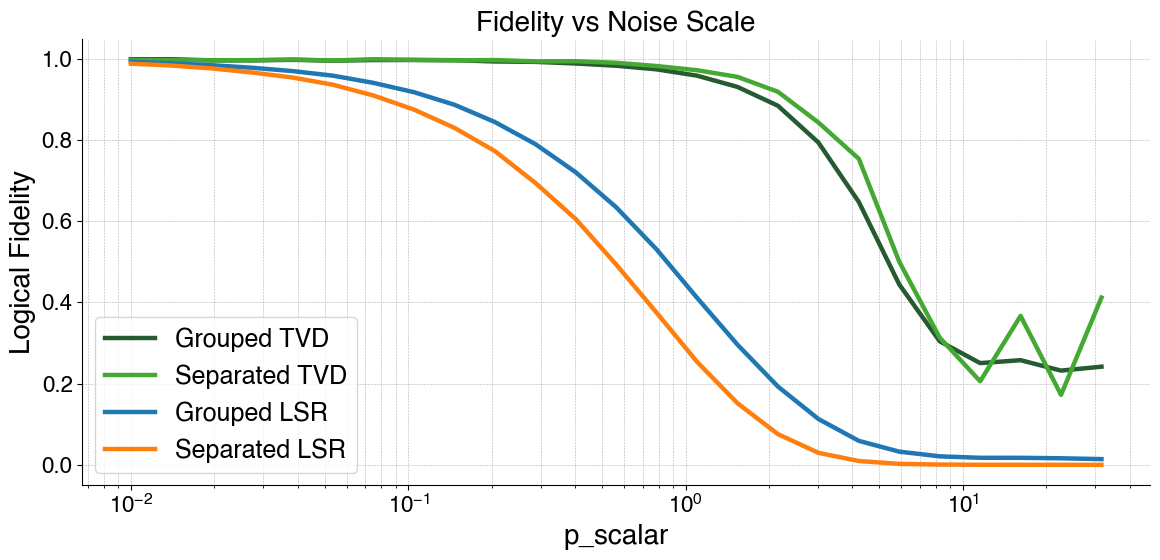

In [29]:
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator

plt.rcParams.update(
    {
        "font.family": "Helvetica",
        "font.sans-serif": "Helvetica",
        "font.size": 20,
        "axes.titlesize": 20,
        "axes.labelsize": 20,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "legend.fontsize": 18,
        "figure.titlesize": 22,
    }
)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(scalars, f_group, color="#265a31", linewidth=3.2, label="Grouped TVD")
ax.plot(scalars, f_diff, color="#44a932", linewidth=3.2, label="Separated TVD")
ax.plot(scalars, lsr_group, color="#1f77b4", linewidth=3.2, label="Grouped LSR")
ax.plot(scalars, lsr_diff, color="#ff7f0e", linewidth=3.2, label="Separated LSR")

ax.set_xscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10, numticks=8))
ax.set_xlabel("p_scalar")
ax.set_ylabel("Logical Fidelity")
ax.set_title("Fidelity vs Noise Scale")

ax.grid(True, which="both", linestyle="--", linewidth=0.4)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ax.legend(loc="lower left", frameon=True)
fig.tight_layout()
fig.savefig("tvd_vs_noise.svg", format="svg", dpi=300)
plt.show()
